# Importing and Querying Data with PostgreSQL (Apartment Data)

## Libraries and Settings

In [27]:
# Libraries
import os
import pandas as pd
from sqlalchemy import create_engine, text
import matplotlib.pyplot as plt

# Settings
import warnings
warnings.filterwarnings("ignore")

# Define settings for graphics
plt.style.use('dark_background')

# Current working directory
print(os.getcwd())

/workspaces/python_postgresql_pgadmin


## Read data to data frame

In [28]:
# Read apartment data
df = pd.read_csv('Data/apartments_data_prepared.csv', sep=',')
df_o = pd.read_csv('Data/Orders.csv', sep=',')
df_c = pd.read_csv('Data/Customers.csv', sep=',')
df_p = pd.read_csv('Data/Products.csv', sep=',')
df_od = pd.read_csv('Data/OrderDetails.csv', sep=',')
df_cat = pd.read_csv('Data/Categories.csv', sep=',')
df_e = pd.read_csv('Data/Employees.csv', sep=',')

df.head(5)

,web-scraper-order,web-scraper-start-url,rooms_area_price_raw,address_raw,price_raw,description_raw,text_raw,rooms,area,price
0,1662023695-433,https://www.immoscout24.ch/de/wohnung/mieten/k...,"3,5 Zimmer, 122 m², CHF 3180.—","Sunnenbergstrasse 15, 8633 Wolfhausen, ZH",CHF 3180.—,"«Grosse Galerie, Terrasse mit Pergola, Berg- u...","3,5 Zimmer, 122 m², CHF 3180.—Sunnenbergstrass...",3.5,122.0,3180.0
1,1662023745-820,https://www.immoscout24.ch/de/wohnung/mieten/k...,"2,5 Zimmer, 78 m², CHF 3760.—","Lavaterstr. 63, 8002 Zürich, ZH",CHF 3760.—,«Wunderschöne Wohnung im Enge-Quartier»,"2,5 Zimmer, 78 m², CHF 3760.—Lavaterstr. 63, 8...",2.5,78.0,3760.0
2,1662023742-807,https://www.immoscout24.ch/de/wohnung/mieten/k...,"5,5 Zimmer, 115 m², CHF 2860.—","Langfurrenstrasse 5c, 8623 Wetzikon ZH, ZH",CHF 2860.—,«Wohnmomente zum Festhalten»,"5,5 Zimmer, 115 m², CHF 2860.—Langfurrenstrass...",5.5,115.0,2860.0
3,1662023804-1290,https://www.immoscout24.ch/de/wohnung/mieten/k...,"3,5 Zimmer, 74 m², CHF 2165.—","Sandbuckweg 5A, 8157 Dielsdorf, ZH",CHF 2165.—,"«3,5 pièces, 74 m²»","top3,5 Zimmer, 74 m², CHF 2165.—Sandbuckweg 5A...",3.5,74.0,2165.0
4,1662023739-771,https://www.immoscout24.ch/de/wohnung/mieten/k...,"5,5 Zimmer, 195 m², CHF 6900.—","Parkring 59, 8002 Zürich, ZH",CHF 6900.—,«Wohnanlage Im Parkring - Exklusive Wohnung zu...,"5,5 Zimmer, 195 m², CHF 6900.—Parkring 59, 800...",5.5,195.0,6900.0


## Create database connection

In [29]:
# Set up database connection
user = "pgadmin"
password = "geheim"
host = "db"
port = "5432"
database = "postgres"

# Erstellen der Connection URL
db_connection_url = "postgresql://" + user + ":" + password +\
                    "@" + host + ":" + port + "/" + database

# Create SQLAlchemy Engine
engine = create_engine(db_connection_url)

# Test database connection
with engine.connect() as connection:
    result = connection.execute(text('SELECT current_database()'))
    print(result.fetchone())

# Dispose the engine
engine.dispose()

('postgres',)


## Write data frame to database table

In [30]:
# Engine für Datenbankverbindung erstellen
engine = create_engine(db_connection_url)

# Schreiben der DataFrames in die Datenbank
df.to_sql('apartment_table', engine, if_exists='replace')
df_c.to_sql('customers', engine, if_exists='replace')
df_o.to_sql('orders', engine, if_exists='replace')
df_p.to_sql('products', engine, if_exists='replace')
df_od.to_sql('orderdetails', engine, if_exists='replace')
df_cat.to_sql('categories', engine, if_exists='replace')
df_e.to_sql('employees', engine, if_exists='replace')

# Datenbankverbindung trennen
engine.dispose()

## List tables in the database

In [31]:
# Create SQLAlchemy Engine
engine = create_engine(db_connection_url)

# Open a connection
with engine.connect() as connection:

    # Execute the query
    result = connection.execute(text("""SELECT table_name
                                        FROM information_schema.tables
                                        WHERE table_schema = 'public'"""))
    
    # Fetch and print the results
    for row in result:
        print(row[0])

# Dispose the engine
engine.dispose()

geography_columns
geometry_columns
spatial_ref_sys
bicycles
apartment_table
sales
salespersons
mechanics
servicerecords
customers
orders
products
orderdetails
categories
employees
customers_table
orders_table


## Make SQL query to select data

In [32]:
# Create SQLAlchemy Engine
engine = create_engine(db_connection_url)

# Write data to table
df_sub = pd.read_sql_query('''SELECT
                                 address_raw,
                                 rooms,
                                 area,
                                 price
                              FROM apartment_table
                              WHERE price >= 1000
                              ORDER BY price DESC;''', 
                          con=engine)

# Dispose the engine
engine.dispose()

# Show the data
df_sub.head().head()

,address_raw,rooms,area,price
0,"Parkring 57, 8002 Zürich, ZH",5.0,187.0,8900.0
1,"Drusbergstrasse 62, 8000 Zürich, ZH",4.5,NaN,7900.0
2,"8053 Zürich, ZH",4.5,171.0,7900.0
3,"Giessereistrasse 12, 8005 Zürich, ZH",2.5,282.0,7500.0
4,"Parkring 59, 8002 Zürich, ZH",5.5,195.0,6900.0


## Plot apartment prices

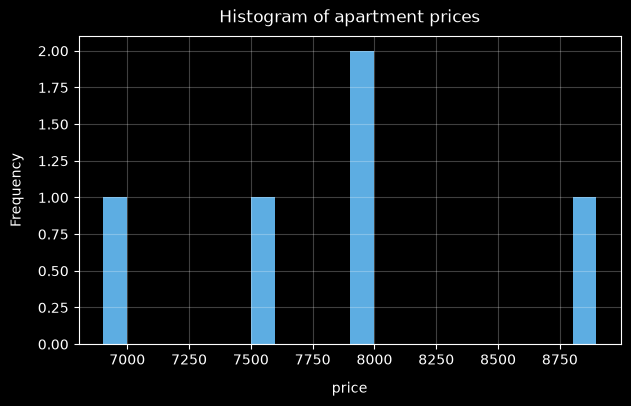

In [33]:
# Plot Histogram
fig = plt.figure( figsize=(7,4))
plt.xticks(fontsize=14, rotation=0)
plt.yticks(fontsize=14, rotation=0)
n, bins, patches = plt.hist(x=df_sub.head()['price'], 
                            bins=20, 
                            color='#5DADE2',
                            alpha=1.00, 
                            rwidth=0.95
                   )
plt.ticklabel_format(style='plain')
plt.grid(alpha=0.25)

# Set labels
plt.xlabel('price', fontsize=10, labelpad=10)
plt.ylabel('Frequency', fontsize=10, labelpad=10)
plt.title('Histogram of apartment prices', fontsize=12, pad=10)

# Set fontsize of tick labels
plt.xticks(fontsize = 10)
plt.yticks(fontsize = 10)

plt.show()

# Questions

## 1

What are the details of all customers whose country is 'Spain'?

In [34]:
# Create SQLAlchemy Engine
engine = create_engine(db_connection_url)

# Write data to table
df_sub = pd.read_sql_query('''SELECT
                            *
                              FROM customers
                              WHERE country = 'Spain';''',
                          con=engine)

# Dispose the engine
engine.dispose()

# Show the data
df_sub.head()

,index,customerid,customername,contactname,address,city,postalcode,country
0,7,8,Bólido Comidas preparadas,Martín Sommer,"C/ Araquil, 67",Madrid,28023,Spain
1,21,22,FISSA Fabrica Inter. Salchichas S.A.,Diego Roel,"C/ Moralzarzal, 86",Madrid,28034,Spain
2,28,29,Galería del gastrónomo,Eduardo Saavedra,"Rambla de Cataluña, 23",Barcelona,8022,Spain
3,29,30,Godos Cocina Típica,José Pedro Freyre,"C/ Romero, 33",Sevilla,41101,Spain
4,68,69,Romero y tomillo,Alejandra Camino,"Gran Vía, 1",Madrid,28001,Spain


## 2

What are the distinct cities of customers from Germany with a city containing the letter 'B'?

In [35]:
# Create SQLAlchemy Engine
engine = create_engine(db_connection_url)

# Write data to table
df_sub = pd.read_sql_query('''SELECT
                            DISTINCT city
                              FROM customers
                              WHERE country = 'Germany'
                              AND city LIKE '%%B%%';''', 
                          con=engine)

# Dispose the engine
engine.dispose()

# Show the data
df_sub.head()

,city
0,Berlin
1,Brandenburg


## 3

What are the number of orders placed by each customer? Sort the result by the number of orders in descending order.

In [36]:
# Create SQLAlchemy Engine
engine = create_engine(db_connection_url)

# Write data to table
df_sub = pd.read_sql_query('''SELECT
                              c.customername, COUNT(o.orderid) as ordersCount
                              FROM customers c
                              LEFT JOIN orders o ON c.customerid = o.customerid
                              GROUP BY c.customerid, c.customername
                              ORDER BY ordersCount DESC;''', 
                          con=engine)

# Dispose the engine
engine.dispose()

# Show the data
df_sub.head()

,customername,orderscount
0,Ernst Handel,10
1,Wartian Herkku,7
2,Rattlesnake Canyon Grocery,7
3,QUICK-Stop,7
4,Split Rail Beer & Ale,6


## 4

What are the customers who have placed more than 3 orders?

In [37]:
# Create SQLAlchemy Engine
engine = create_engine(db_connection_url)

# Write data to table
df_sub = pd.read_sql_query('''SELECT
                              c.customername, COUNT(o.orderid) as ordersCount
                              FROM customers c
                              LEFT JOIN orders o ON c.customerid = o.customerid
                              GROUP BY c.customerid, c.customername
                              HAVING COUNT(o.orderid) >= 3
                              ORDER BY ordersCount DESC;''', 
                          con=engine)

# Dispose the engine
engine.dispose()

# Show the data
df_sub.head()

,customername,orderscount
0,Ernst Handel,10
1,QUICK-Stop,7
2,Wartian Herkku,7
3,Rattlesnake Canyon Grocery,7
4,Hungry Owl All-Night Grocers,6


## 5

What are the top 5 most expensive products? Round the price to 2 decimal places.

In [38]:
# Create SQLAlchemy Engine
engine = create_engine(db_connection_url)

# Write data to table
df_sub = pd.read_sql_query('''SELECT
                                productname,
                                ROUND(CAST(price AS NUMERIC), 2) AS Price
                              FROM products
                              ORDER BY price DESC
                              LIMIT 5;''', 
                          con=engine)

# Dispose the engine
engine.dispose()

# Show the data
df_sub.head()

,productname,price
0,Côte de Blaye,263.50
1,Thüringer Rostbratwurst,123.79
2,Mishi Kobe Niku,97.00
3,Sir Rodney's Marmalade,81.00
4,Carnarvon Tigers,62.50


## 6

What are the order details (ProductID, Quantity) for customers from France?

In [39]:
# Create SQLAlchemy Engine
engine = create_engine(db_connection_url)

# Write data to table
df_sub = pd.read_sql_query('''SELECT
                                od.productid, SUM(od.quantity)
                              FROM customers c
                              LEFT JOIN orders o ON o.customerid = c.customerid
                              LEFT JOIN orderdetails od ON od.orderid = o.orderid
                              WHERE c.country = 'France'
                              GROUP BY od.productid;''', 
                          con=engine)

# Dispose the engine
engine.dispose()

# Show the data
df_sub.head()

,productid,sum
0,NaN,NaN
1,42.0,6.0
2,29.0,35.0
3,54.0,73.0
4,71.0,20.0


## 7

Area there products without a category assigned?

In [40]:
# Create SQLAlchemy Engine
engine = create_engine(db_connection_url)

# Write data to table
df_sub = pd.read_sql_query('''SELECT 
    ProductID, 
    ProductName,
    CategoryID
FROM Products
WHERE CategoryID IS NULL;''', 
                          con=engine)

# Dispose the engine
engine.dispose()

# Show the data
df_sub.head()

,productid,productname,categoryid


## 8

What are all orders and their employees?

In [41]:
# Create SQLAlchemy Engine
engine = create_engine(db_connection_url)

# Write data to table
df_sub = pd.read_sql_query('''SELECT
                            COUNT(o.orderid) AS orderCount,e.employeeid, e.firstname, e.lastname
                              FROM orders o
                              LEFT JOIN employees e ON o.employeeid = e.employeeid
                              GROUP BY e.firstname, e.lastname, e.employeeid
                              ORDER BY orderCount DESC
                              ;''', 
                          con=engine)

# Dispose the engine
engine.dispose()

# Show the data
df_sub.head()

,ordercount,employeeid,firstname,lastname
0,40,4,Margaret,Peacock
1,31,3,Janet,Leverling
2,29,1,Nancy,Davolio
3,27,8,Laura,Callahan
4,20,2,Andrew,Fuller


## 9

What is the average, minimum, and maximum price of products? Round the values to 2 decimal places.

In [42]:
# Create SQLAlchemy Engine
engine = create_engine(db_connection_url)

# Write data to table
df_sub = pd.read_sql_query('''SELECT 
    ROUND(CAST(AVG(Price) AS NUMERIC), 2) AS AveragePrice,
    ROUND(CAST(MIN(Price) AS NUMERIC), 2) AS MinimumPrice,
    ROUND(CAST(MAX(Price) AS NUMERIC), 2) AS MaximumPrice
FROM Products;''', 
                          con=engine)

# Dispose the engine
engine.dispose()

# Show the data
df_sub.head()

,averageprice,minimumprice,maximumprice
0,28.87,2.5,263.5


## 10

What are the products with prices between 10 and 50? Round the price to 2 decimal places and sort the result by price in descending order.

In [43]:
# Create SQLAlchemy Engine
engine = create_engine(db_connection_url)

# Write data to table
df_sub = pd.read_sql_query('''SELECT
                            productname, ROUND(CAST(price AS NUMERIC), 2) AS Price
                              FROM products
                              WHERE price BETWEEN 10 AND 50
                              ORDER BY Price DESC;''', 
                          con=engine)

# Dispose the engine
engine.dispose()

# Show the data
df_sub.head().head()

,productname,price
0,Tarte au sucre,49.3
1,Ipoh Coffee,46.0
2,Rössle Sauerkraut,45.6
3,Schoggi Schokolade,43.9
4,Vegie-spread,43.9


## 11

What are the shippers and the total number of orders shipped by each shipper, including those with no orders?

In [44]:
# Create SQLAlchemy Engine
engine = create_engine(db_connection_url)

# Write data to table
df_sub = pd.read_sql_query('''SELECT
                            *
                              FROM customers
                              WHERE country = 'Spain';''', 
                          con=engine)

# Dispose the engine
engine.dispose()

# Show the data
df_sub.head()

,index,customerid,customername,contactname,address,city,postalcode,country
0,7,8,Bólido Comidas preparadas,Martín Sommer,"C/ Araquil, 67",Madrid,28023,Spain
1,21,22,FISSA Fabrica Inter. Salchichas S.A.,Diego Roel,"C/ Moralzarzal, 86",Madrid,28034,Spain
2,28,29,Galería del gastrónomo,Eduardo Saavedra,"Rambla de Cataluña, 23",Barcelona,8022,Spain
3,29,30,Godos Cocina Típica,José Pedro Freyre,"C/ Romero, 33",Sevilla,41101,Spain
4,68,69,Romero y tomillo,Alejandra Camino,"Gran Vía, 1",Madrid,28001,Spain


## 12

What are the employees who have processed > 5 orders? Sort the result by the number of orders in descending order.

In [45]:
# Create SQLAlchemy Engine
engine = create_engine(db_connection_url)

# Write data to table
df_sub = pd.read_sql_query('''SELECT
                            *
                              FROM customers
                              WHERE country = 'Spain';''', 
                          con=engine)

# Dispose the engine
engine.dispose()

# Show the data
df_sub.head()

,index,customerid,customername,contactname,address,city,postalcode,country
0,7,8,Bólido Comidas preparadas,Martín Sommer,"C/ Araquil, 67",Madrid,28023,Spain
1,21,22,FISSA Fabrica Inter. Salchichas S.A.,Diego Roel,"C/ Moralzarzal, 86",Madrid,28034,Spain
2,28,29,Galería del gastrónomo,Eduardo Saavedra,"Rambla de Cataluña, 23",Barcelona,8022,Spain
3,29,30,Godos Cocina Típica,José Pedro Freyre,"C/ Romero, 33",Sevilla,41101,Spain
4,68,69,Romero y tomillo,Alejandra Camino,"Gran Vía, 1",Madrid,28001,Spain


## 13

What is the total revenue for each product within each order, including the product name and ordered by order ID and total revenue in descending order?

In [46]:
# Create SQLAlchemy Engine
engine = create_engine(db_connection_url)

# Write data to table
df_sub = pd.read_sql_query('''SELECT
                            p.productname, od.orderid, SUM(p.price * od.Quantity) AS revenue
                              FROM orderdetails od
                              JOIN products p ON p.productid = od.productid
                              GROUP BY p.productid, od.orderid, p.productname
                              ORDER BY od.orderid, revenue DESC;''', 
                          con=engine)

# Dispose the engine
engine.dispose()

# Show the data
df_sub.head()

,productname,orderid,revenue
0,Queso Cabrales,10248,252.00
1,Mozzarella di Giovanni,10248,174.00
2,Singaporean Hokkien Fried Mee,10248,140.00
3,Manjimup Dried Apples,10249,2120.00
4,Tofu,10249,209.25


## 14

What are the customers, employees, and the total number of orders placed by each customer?

In [ ]:
# Create SQLAlchemy Engine
engine = create_engine(db_connection_url)

# Write data to table
df_sub = pd.read_sql_query('''SELECT
                            c.customerid, COUNT(o.orderid) AS OrdersCount, e.firstname
                              FROM customers c
                              JOIN orders o ON o.customerid = c.customerid
                              JOIN employees e ON e.employeeid = o.employeeid
                              GROUP BY c.customerid, e.firstname
                              ORDER BY OrdersCount DESC
                              ;''', 
                          con=engine)

# Dispose the engine
engine.dispose()

# Show the data
df_sub.head()

,customerid,orderscount,firstname
0,25,3,Margaret
1,87,3,Laura
2,20,3,Margaret
3,65,3,Nancy
4,46,3,Janet


## 15

What are the products with an average price higher than the overall average product price? Round the price to 2 decimal places and sort the result by price in descending order.

In [ ]:
# Create SQLAlchemy Engine
engine = create_engine(db_connection_url)

# Write data to table
df_sub = pd.read_sql_query('''SELECT
                            productname, ROUND(CAST(price AS NUMERIC), 2) AS Price
                              FROM products
                              WHERE Price > (SELECT AVG(Price) FROM Products)
                              ORDER BY Price DESC;''', 
                          con=engine)

# Dispose the engine
engine.dispose()

# Show the data
df_sub.head()

,productname,price
0,Côte de Blaye,263.50
1,Thüringer Rostbratwurst,123.79
2,Mishi Kobe Niku,97.00
3,Sir Rodney's Marmalade,81.00
4,Carnarvon Tigers,62.50


### Jupyter notebook --footer info-- (please always provide this at the end of each notebook)

In [ ]:
import os
import platform
from platform import python_version
from datetime import datetime

print('-----------------------------------')
print(os.name.upper())
print(platform.system(), '|', platform.release())
print('Datetime:', datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
print('Python Version:', python_version())
print('-----------------------------------')

-----------------------------------
POSIX
Linux | 7.0.14-linuxkit
Datetime: 2026-11-06 18:22:42
Python Version: 3.12.15
-----------------------------------
